# A25 三个团队合作节省的成本怎样分配？

输入每个团队联盟可创造的节省额。比较平均分、按投入分和Shapley值，另行检查任何联盟是否愿意退出；公平原则与稳定性要分别讨论。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 联盟价值不是个人成本
用frozenset表示联盟，字典值是该联盟相对独立行动创造的可分配节省额。所有7个非空联盟都要给出数值，不能只知道大联盟收益就计算Shapley值。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

names=["甲","乙","丙"];players=tuple(range(3))
worth={frozenset():0.,frozenset([0]):0.,frozenset([1]):0.,frozenset([2]):0.,
       frozenset([0,1]):8.,frozenset([0,2]):6.,frozenset([1,2]):4.,frozenset([0,1,2]):12.}
def all_coalitions(n):
    return [frozenset(s) for size in range(n+1) for s in itertools.combinations(range(n),size)]
assert set(worth)==set(all_coalitions(3))
pd.DataFrame([dict(coalition="".join(names[i] for i in sorted(s)) or "空",saving=v) for s,v in worth.items()]).to_csv(DATA_DIR/"联盟价值.csv",index=False,encoding="utf-8-sig")


## 2. Shapley：平均边际贡献
遍历6种加入顺序，每次计算新成员使联盟价值增加多少。平均后得到每人分配。它依据一组公平公理，不代表每个人都一定接受。

In [3]:
def shapley(values,n):
    allocation=np.zeros(n);orders=list(itertools.permutations(range(n)))
    for order in orders:
        before=frozenset()
        for person in order:
            after=before|{person}
            allocation[person]+=values[after]-values[before]
            before=after
    return allocation/len(orders)
allocation=shapley(worth,3)
assert np.isclose(allocation.sum(),worth[frozenset(players)]-worth[frozenset()])
equal=np.full(3,worth[frozenset(players)]/3)
effort=np.array([5.,3.,2.]);proportional=effort/effort.sum()*worth[frozenset(players)]


## 3. 单独检查个体和联盟接受条件
如果某联盟成员分到的总额小于它独立合作能得到的价值，这个联盟有离开的利益。满足所有联盟条件且总额守恒称为核心中的分配；Shapley值不保证总在核心中。

In [4]:
def blocking_coalitions(shares,values):
    return [s for s in values if s and sum(shares[i] for i in s)<values[s]-1e-8]
def in_core(shares,values):
    n=len(shares)
    return np.isclose(sum(shares),values[frozenset(range(n))]) and not blocking_coalitions(shares,values)
schemes={"平均":equal,"投入比例":proportional,"Shapley":allocation}
core_results={name:in_core(shares,worth) for name,shares in schemes.items()}
# 三人简单多数游戏：任意两人值1，大联盟值1，其Shapley均分但任意两人想退出。
majority={s:float(len(s)>=2) for s in all_coalitions(3)}
majority_shapley=shapley(majority,3)
assert np.allclose(majority_shapley,[1/3]*3)
assert not in_core(majority_shapley,majority)


## 4. 输出公平原则与稳定性对照
表中列出不同规则分配及被哪些联盟反对。投入比例依赖投入测量，Shapley依赖所有联盟价值；真实价值估计有误时，应做敏感性检查再谈谈判建议。

In [5]:
table=pd.DataFrame(schemes,index=names)
table.to_csv(OUT_DIR/"节省额分配.csv",encoding="utf-8-sig")
table.plot.bar();plt.ylabel("分得节省额");plt.xticks(rotation=0)
plt.tight_layout();plt.savefig(OUT_DIR/"合作分配.png");plt.close()
blocking={name:[sorted(s) for s in blocking_coalitions(shares,worth)] for name,shares in schemes.items()}
save_results({"shapley":allocation.tolist(),"equal":equal.tolist(),"proportional":proportional.tolist(),
              "in_core":core_results,"blocking_coalitions":blocking,"majority_counterexample":majority_shapley.tolist()},
             f"本联盟价值下Shapley分配为{np.round(allocation,3).tolist()}，是否在核心：{core_results['Shapley']}。"
             f"三种规则的联盟阻挡检查为{blocking}。建议先确认所采用的公平原则，再核查联盟退出激励；Shapley并非自动稳定。")


{
  "shapley": [
    5.0,
    4.0,
    3.0
  ],
  "equal": [
    4.0,
    4.0,
    4.0
  ],
  "proportional": [
    6.0,
    3.5999999999999996,
    2.4000000000000004
  ],
  "in_core": {
    "平均": true,
    "投入比例": true,
    "Shapley": true
  },
  "blocking_coalitions": {
    "平均": [],
    "投入比例": [],
    "Shapley": []
  },
  "majority_counterexample": [
    0.3333333333333333,
    0.3333333333333333,
    0.3333333333333333
  ]
}
本联盟价值下Shapley分配为[5.0, 4.0, 3.0]，是否在核心：True。三种规则的联盟阻挡检查为{'平均': [], '投入比例': [], 'Shapley': []}。建议先确认所采用的公平原则，再核查联盟退出激励；Shapley并非自动稳定。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

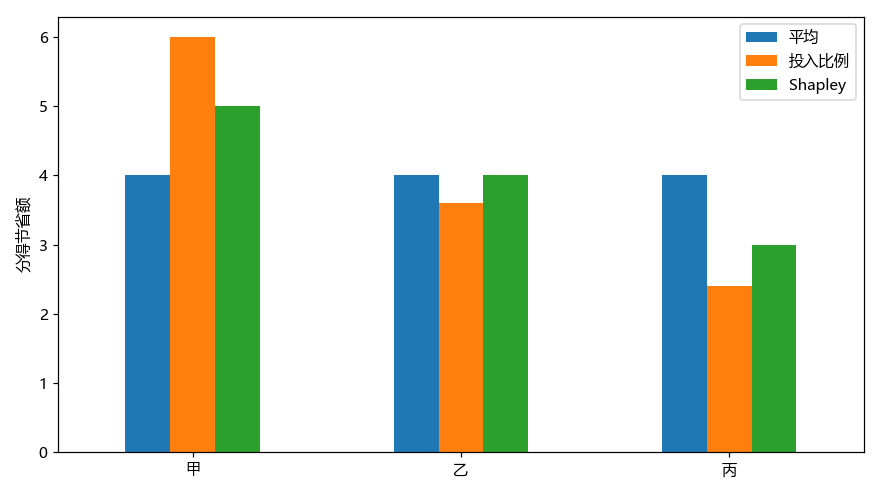

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
采用可转移效用合作博弈，所有联盟价值为教学假设。Shapley值满足其公平公理但不保证联盟稳定；真实谈判还涉及非金钱偏好和退出成本。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。